# Análisis exploratorio de datos: Steam Games Dataset

## 1. Origen de los datos
- **Conjunto de datos:** *Steam Games Dataset* (autor: FronkonGames), publicado en Kaggle. Enlace: https://www.kaggle.com/datasets/fronkongames/steam-games-dataset
- **Licencia:** MIT.
- **Fecha de descarga:** 10/11/2026 · **Última actualización indicada en Kaggle:** 8/11/2026 (se actualiza cada 5 días)
- **Procedencia de las variables:** metadatos de la tienda de Steam y estimaciones de propietarios de SteamSpy [verificar en la ficha del dataset].
- **Limitación:** las ventas reales no son públicas; `Estimated owners` es una estimación por rangos, no un dato exacto.

## 2. Objetivos del análisis exploratorio
1. Describir la estructura, la cobertura temporal y la calidad del conjunto de datos.
2. Comparar dos definiciones operativas de juego indie (género y etiqueta).
3. Caracterizar la evolución anual de los lanzamientos y de su proporción indie.
4. Identificar limitaciones que condicionen la variable objetivo y el modelo predictivo.

## 3. Variables utilizadas

| Variable | Descripción | Uso previsto |
|---|---|---|
| `AppID` | Identificador del juego en Steam | Clave única |
| `Name` | Título | Identificación |
| `Release date` | Fecha de lanzamiento | Análisis temporal; ventana de madurez |
| `Estimated owners` | Rango estimado de propietarios | Base de la variable objetivo |
| `Peak CCU` | Pico de usuarios concurrentes | Candidata a variable objetivo o explicativa |
| `Price` | Precio | Variable explicativa |
| `Positive`, `Negative` | Reseñas positivas y negativas | Reseñas totales; indicador de éxito |
| `Metacritic score` | Puntuación de la crítica | Variable explicativa (cobertura a comprobar) |
| `Genres`, `Tags` | Géneros y etiquetas | Definición de indie; variables explicativas |
| `Developers`, `Publishers` | Desarrolladores y editores | Variables explicativas |
| `Supported languages` | Idiomas admitidos | Variable explicativa |
| `Windows`, `Mac`, `Linux` | Plataformas | Variables explicativas |

El resto de columnas del archivo original se descarta por no ser relevantes para el estudio o por contener datos de contacto de los desarrolladores.

## 4. Carga de los datos

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA = "data/kaggle/steam_games_dataset/games.csv"
FECHA_CORTE = pd.Timestamp("2026-11-13")   # fecha de la descarga
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

# La cabecera original fusiona dos columnas ("DiscountDLC count"); se separan.
cols = pd.read_csv(RUTA, nrows=0).columns.tolist()
cols = sum([["Discount", "DLC count"] if c == "DiscountDLC count" else [c] for c in cols], [])

usar = ["AppID", "Name", "Release date", "Estimated owners", "Peak CCU", "Price",
        "Positive", "Negative", "Metacritic score", "Genres", "Tags",
        "Developers", "Publishers", "Supported languages", "Windows", "Mac", "Linux"]
df = pd.read_csv(RUTA, header=0, names=cols, usecols=usar)
print("Registros y columnas cargados:", df.shape)

Registros y columnas cargados: (125855, 17)


## 5. Limpieza y transformación
1. **Duplicados:** se conserva un único registro por `AppID`.
2. **Fechas:** se convierten a formato fecha; las no interpretables quedan como nulas.
3. **Fechas futuras:** se excluyen los juegos con fecha posterior a la descarga (aún no lanzados).
4. **Propietarios:** el rango textual se transforma en dos variables numéricas (mínimo y máximo).
5. **Reseñas:** se calcula el total (positivas + negativas).
6. **Indie:** se definen dos variables (por `Genres` y por `Tags`). Si el campo de origen es nulo, el valor queda como desconocido y no se interpreta como «no indie».

In [ ]:
n_inicial = len(df)
df = df.drop_duplicates("AppID")
n_dup = n_inicial - len(df)

df["fecha"] = pd.to_datetime(df["Release date"], errors="coerce", format="mixed")
df["anio"] = df["fecha"].dt.year
n_futuros = (df["fecha"] > FECHA_CORTE).sum()
df = df[df["fecha"].isna() | (df["fecha"] <= FECHA_CORTE)]

rango = df["Estimated owners"].str.extract(r"(\d[\d,]*)\D+(\d[\d,]*)")
df["owners_min"] = rango[0].str.replace(",", "").astype(float)
df["owners_max"] = rango[1].str.replace(",", "").astype(float)

df["resenas"] = df["Positive"].fillna(0) + df["Negative"].fillna(0)

df["indie_genres"] = df["Genres"].str.contains("Indie").astype("boolean")
df["indie_tags"] = df["Tags"].str.contains("Indie").astype("boolean")

print(f"Duplicados eliminados: {n_dup} | Fechas futuras eliminadas: {n_futuros} | Registros finales: {len(df)}")

Duplicados eliminados: 0 | Fechas futuras eliminadas: 1 | Registros finales: 125854


## 6. Calidad de los datos

In [ ]:
print("Proporción de nulos por columna (mayores):")
print(df.isna().mean().round(3).sort_values(ascending=False).head(8))
print("\nRango de fechas:", df["fecha"].min().date(), "-", df["fecha"].max().date())
print("\nDistribución de propietarios estimados:")
print(df["Estimated owners"].value_counts(normalize=True).head(8).round(3))
print("\nJuegos con menos de 10 reseñas:", round((df["resenas"] < 10).mean(), 3))

Proporción de nulos por columna (mayores):
Tags                0.338
Publishers          0.071
Developers          0.067
Genres              0.067
AppID               0.000
Name                0.000
Release date        0.000
Estimated owners    0.000
dtype: float64

Rango de fechas: 1997-06-30 - 2026-09-08

Distribución de propietarios estimados:
Estimated owners
0 - 20000            0.602
0 - 0                0.195
20000 - 50000        0.091
50000 - 100000       0.043
100000 - 200000      0.027
200000 - 500000      0.023
500000 - 1000000     0.009
1000000 - 2000000    0.006
Name: proportion, dtype: float64

Juegos con menos de 10 reseñas: 0.55


## 7. Definición de juego indie: género frente a etiqueta
Se comparan ambas definiciones únicamente entre los juegos con `Genres` y `Tags` informados.

In [ ]:
c = df[df["indie_genres"].notna() & df["indie_tags"].notna()]
print("Juegos comparables:", len(c))
print(pd.crosstab(c["indie_genres"], c["indie_tags"], margins=True))
print("Concordancia entre definiciones:", round((c["indie_genres"] == c["indie_tags"]).mean(), 3))
print("Proporción indie (Genres):", round(c["indie_genres"].mean(), 3),
      "| (Tags):", round(c["indie_tags"].mean(), 3))

Juegos comparables: 125854
indie_tags    False   True     All
indie_genres                      
False         40526   2445   42971
True          36772  46111   82883
All           77298  48556  125854
Concordancia entre definiciones: 0.688
Proporción indie (Genres): 0.659 | (Tags): 0.386


## 8. Evolución anual (2010-2025)
Se excluye 2026 por estar incompleto. Para la proporción indie, los valores desconocidos no se incluyen en el cálculo.

In [ ]:
d = df[df["anio"].between(2010, 2025)]
por_anio = d.groupby("anio").agg(
    juegos=("AppID", "size"),
    pct_indie_genres=("indie_genres", "mean"),
    pct_indie_tags=("indie_tags", "mean"),
    pct_menos10=("resenas", lambda s: (s < 10).mean()),
).round(3)

# Cobertura de propietarios entre juegos con menos de 10 reseñas
por_anio["pct_owners_cero"] = (d[d["resenas"] < 10].groupby("anio")["owners_max"]
                               .apply(lambda s: (s == 0).mean()).round(3))
print(por_anio)

      juegos  pct_indie_genres  pct_indie_tags  pct_menos10  pct_owners_cero
anio                                                                        
2010     255             0.267           0.302        0.055            0.071
2011     260             0.408           0.408        0.008            0.000
2012     322             0.519           0.506        0.003            0.000
2013     468             0.556           0.556        0.051            0.875
2014    1523             0.575           0.587        0.016            0.320
2015    2515             0.728           0.732        0.043            0.112
2016    4141             0.705           0.712        0.096            0.038
2017    5922             0.712           0.712        0.214            0.015
2018    7461             0.769           0.744        0.280            0.013
2019    7243              0.76           0.695        0.350            0.007
2020    8804             0.744           0.612        0.366            0.024

## 9. Representaciones gráficas

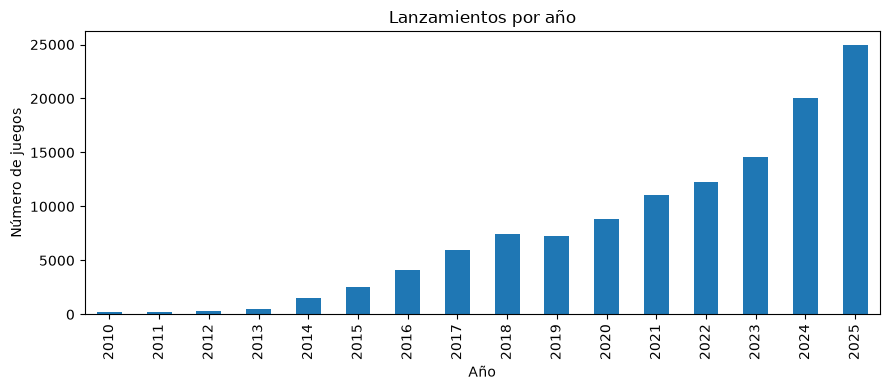

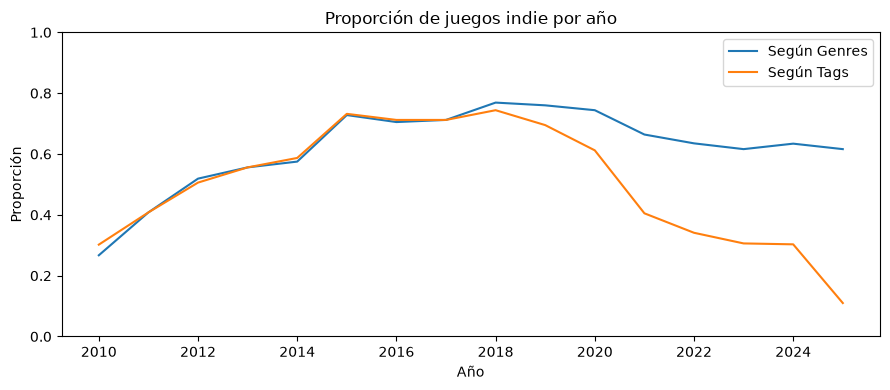

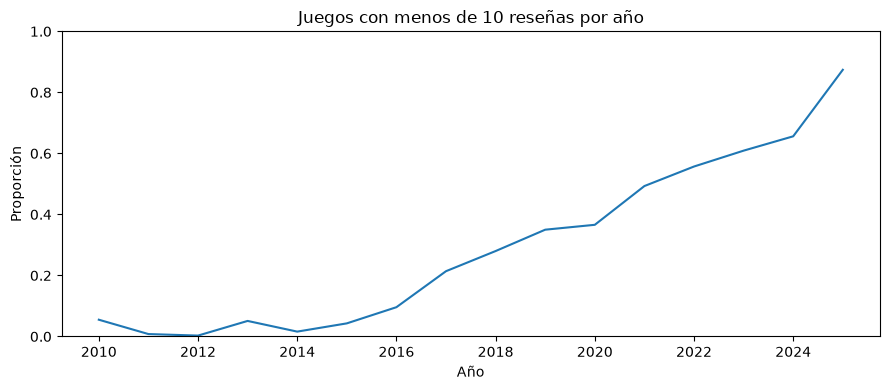

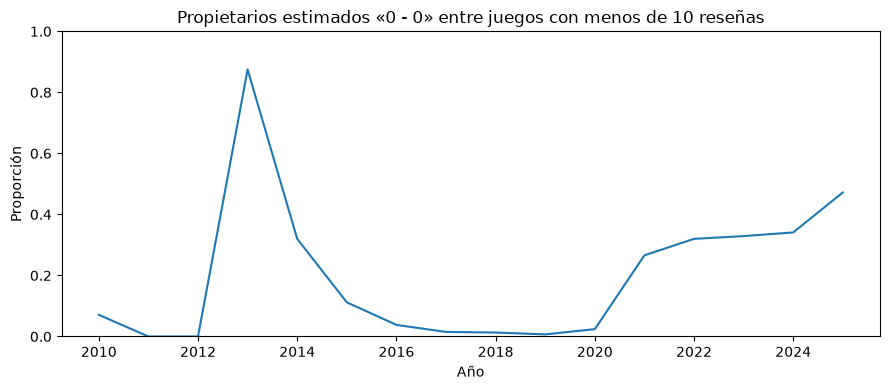

In [ ]:
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / f"{nombre}.png", dpi=150); plt.show()

por_anio["juegos"].plot(kind="bar", figsize=(9, 4))
plt.title("Lanzamientos por año"); plt.xlabel("Año"); plt.ylabel("Número de juegos")
guardar("lanzamientos_anio")

por_anio[["pct_indie_genres", "pct_indie_tags"]].plot(figsize=(9, 4))
plt.title("Proporción de juegos indie por año"); plt.xlabel("Año"); plt.ylabel("Proporción")
plt.legend(["Según Genres", "Según Tags"]); plt.ylim(0, 1)
guardar("pct_indie_anio")

por_anio["pct_menos10"].plot(figsize=(9, 4))
plt.title("Juegos con menos de 10 reseñas por año"); plt.xlabel("Año"); plt.ylabel("Proporción")
plt.ylim(0, 1)
guardar("pct_menos10_anio")

por_anio["pct_owners_cero"].plot(figsize=(9, 4))
plt.title("Propietarios estimados «0 - 0» entre juegos con menos de 10 reseñas")
plt.xlabel("Año"); plt.ylabel("Proporción"); plt.ylim(0, 1)
guardar("owners_cero_anio")

## 10. Hallazgos
1. **Cola larga:** el 55 % de los juegos tiene menos de 10 reseñas y el 60,2 % está en el tramo «0 - 20.000» de propietarios (19,5 % en «0 - 0»). La mayoría de los títulos obtiene resultados muy modestos.
2. **Saturación creciente:** la proporción con menos de 10 reseñas pasa del 4 % (2015) al 66 % (2024).
3. **Definición de indie:** `Genres` es más amplia que `Tags` (71,6 % frente a 58,3 % entre los comparables) y coinciden en el 80,8 % de los casos.
4. **Cobertura de propietarios:** entre juegos con menos de 10 reseñas, el tramo «0 - 0» pasa del 2,4 % (2020) al 26,6 % (2021). Ningún juego con 50 o más reseñas aparece en «0 - 0» en ningún año, lo que sugiere un cambio en la cobertura de la fuente para los juegos de muy poca actividad.
5. **Datos recientes:** 2026 está incompleto y los juegos recientes acumulan menos reseñas, por lo que no son comparables con los antiguos.

## 11. Decisiones para el modelado
- El análisis descriptivo se limita a 2010-2025.
- El modelo predictivo se entrenará solo con juegos con una ventana mínima de madurez desde su lanzamiento [fijar entre 12 y 24 meses].
- El tramo «0 - 0» se tratará como «sin actividad apreciable» y se documentará como limitación.
- La definición principal de indie será `Genres`, con `Tags` como análisis de sensibilidad.
- Los propietarios estimados se contrastarán con los de SteamSpy como trabajo posterior.